<a href="https://colab.research.google.com/github/patrickmurayari/tpi-ia-patologias-tomate/blob/main/notebooks/02_baseline_clasico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import os
import json
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = Path("/content/plantvillage_tomate")
RAW_DIR = BASE_DIR / "raw"
RESULTS_DIR = BASE_DIR / "results_baseline"
RAW_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Leemos el manifiesto exacto desde tu repositorio público de GitHub
GITHUB_CSV_URL = "https://raw.githubusercontent.com/patrickmurayari/tpi-ia-patologias-tomate/main/data/tomate_splits_seed42.csv"
GITHUB_CSV_URL_ROOT = "https://raw.githubusercontent.com/patrickmurayari/tpi-ia-patologias-tomate/main/tomate_splits_seed42.csv"

df_splits = None

try:
    print(f"Intentando cargar desde: {GITHUB_CSV_URL}")
    df_splits = pd.read_csv(GITHUB_CSV_URL)
except Exception as e_primary:
    print(f"No se pudo cargar la URL principal. Error: {e_primary}")
    try:
        print(f"Intentando fallback desde: {GITHUB_CSV_URL_ROOT}")
        df_splits = pd.read_csv(GITHUB_CSV_URL_ROOT)
    except Exception as e_fallback:
        print(f"No se pudo cargar la URL de fallback. Error: {e_fallback}")
        print("\n[ERROR] No se pudo obtener el archivo CSV. Por favor, verifica que:")
        print("1. El repositorio sea público.")
        print("2. La rama sea 'main' (o cámbiala por 'master' si corresponde).")
        print("3. El archivo 'tomate_splits_seed42.csv' exista en la ruta especificada.")

if df_splits is not None:
    print(f"\nManifiesto cargado correctamente: {len(df_splits)} registros.")
    print(df_splits["split"].value_counts())
else:
    print("\nNo se pudo inicializar df_splits debido a los errores anteriores.")

Intentando cargar desde: https://raw.githubusercontent.com/patrickmurayari/tpi-ia-patologias-tomate/main/data/tomate_splits_seed42.csv

Manifiesto cargado correctamente: 18146 registros.
split
train    12702
val       2722
test      2722
Name: count, dtype: int64


In [13]:
%%bash
cd /content/plantvillage_tomate/raw
if [ ! -d "PlantVillage-Dataset" ]; then
    git clone --filter=blob:none --no-checkout --depth 1 https://github.com/spmohanty/PlantVillage-Dataset.git
    cd PlantVillage-Dataset
    git sparse-checkout init --cone
    git sparse-checkout set "raw/color/Tomato___Bacterial_spot" \
                            "raw/color/Tomato___Early_blight" \
                            "raw/color/Tomato___Late_blight" \
                            "raw/color/Tomato___Leaf_Mold" \
                            "raw/color/Tomato___Septoria_leaf_spot" \
                            "raw/color/Tomato___Spider_mites Two-spotted_spider_mite" \
                            "raw/color/Tomato___Target_Spot" \
                            "raw/color/Tomato___Tomato_Yellow_Leaf_Curl_Virus" \
                            "raw/color/Tomato___Tomato_mosaic_virus" \
                            "raw/color/Tomato___healthy"
    git checkout
else
    echo "Imágenes ya disponibles en disco local."
fi

Your branch is up to date with 'origin/master'.


Cloning into 'PlantVillage-Dataset'...


In [14]:
DATASET_REPO_ROOT = RAW_DIR / "PlantVillage-Dataset"

def extract_classical_features(rel_path: str) -> np.ndarray:
    """
    Convierte una imagen en un vector tabular de 102 características:
    - 96 bins de histogramas normalizados en espacio HSV (32 por canal)
    - 6 estadísticos de gradientes y bordes en escala de grises (Sobel X/Y y Laplaciano)
    """
    full_path = str(DATASET_REPO_ROOT / rel_path)
    img_bgr = cv2.imread(full_path)

    # Estandarizamos tamaño
    img_bgr = cv2.resize(img_bgr, (256, 256))

    # 1. Características de Color (HSV)
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    hist_h = cv2.calcHist([img_hsv], [0], None, [32], [0, 180]).flatten()
    hist_s = cv2.calcHist([img_hsv], [1], None, [32], [0, 256]).flatten()
    hist_v = cv2.calcHist([img_hsv], [2], None, [32], [0, 256]).flatten()

    # Normalización L1 para invariancia a escala
    hist_h /= (hist_h.sum() + 1e-7)
    hist_s /= (hist_s.sum() + 1e-7)
    hist_v /= (hist_v.sum() + 1e-7)

    # 2. Características de Textura y Bordes (Escala de grises)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)

    texture_feats = np.array([
        np.mean(np.abs(sobel_x)), np.std(sobel_x),
        np.mean(np.abs(sobel_y)), np.std(sobel_y),
        np.mean(np.abs(laplacian)), np.std(laplacian)
    ], dtype=np.float32)

    return np.concatenate([hist_h, hist_s, hist_v, texture_feats])

# Extracción para todo el dataset (tarda ~25-40 segundos en Colab)
features_list = []
for rel_p in tqdm(df_splits["rel_path"], desc="Extrayendo atributos HSV + Textura"):
    features_list.append(extract_classical_features(rel_p))

X_all = np.vstack(features_list)
y_all = df_splits["label_idx"].values

# Separación estricta según el split fijado
train_mask = (df_splits["split"] == "train").values
val_mask   = (df_splits["split"] == "val").values
test_mask  = (df_splits["split"] == "test").values

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val     = X_all[val_mask],   y_all[val_mask]
X_test, y_test   = X_all[test_mask],  y_all[test_mask]

print(f"Matrices listas -> Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Extrayendo atributos HSV + Textura:   0%|          | 0/18146 [00:00<?, ?it/s]

Matrices listas -> Train: (12702, 102), Val: (2722, 102), Test: (2722, 102)


In [15]:
# Probamos dos familias clásicas con balanceo de clases
candidatos = {
    "LogisticRegression_L2": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0, random_state=SEED)
    ),
    "RandomForest_100": RandomForestClassifier(
        n_estimators=100, max_depth=20, class_weight="balanced", n_jobs=-1, random_state=SEED
    ),
    "RandomForest_300": RandomForestClassifier(
        n_estimators=300, max_depth=None, class_weight="balanced", n_jobs=-1, random_state=SEED
    )
}

resultados_val = []
best_model = None
best_val_f1 = -1.0
best_name = ""

for nombre, clf in candidatos.items():
    clf.fit(X_train, y_train)
    preds_val = clf.predict(X_val)

    acc_v = accuracy_score(y_val, preds_val)
    f1_macro_v = f1_score(y_val, preds_val, average="macro")

    resultados_val.append({
        "Modelo": nombre,
        "Val_Accuracy": round(acc_v, 4),
        "Val_Macro_F1": round(f1_macro_v, 4)
    })

    if f1_macro_v > best_val_f1:
        best_val_f1 = f1_macro_v
        best_model = clf
        best_name = nombre

df_val_comp = pd.DataFrame(resultados_val)
display(df_val_comp)
print(f"\nMejor modelo seleccionado en Validación: {best_name} (Macro F1 = {best_val_f1:.4f})")

,Modelo,Val_Accuracy,Val_Macro_F1
0,LogisticRegression_L2,0.9019,0.8920
1,RandomForest_100,0.9589,0.9544
2,RandomForest_300,0.9578,0.9533



Mejor modelo seleccionado en Validación: RandomForest_100 (Macro F1 = 0.9544)


=== RESULTADOS FINALES BASELINE EN TEST (RandomForest_100) ===
Accuracy Global : 0.9559
Macro F1-Score  : 0.9541
Weighted F1     : 0.9556

Reporte detallado por patología:
                                      precision    recall  f1-score   support

                      Bacterial_spot     0.9453    0.9216    0.9333       319
                        Early_blight     0.9840    0.8200    0.8945       150
                         Late_blight     0.9479    0.9579    0.9529       285
                           Leaf_Mold     0.9853    0.9371    0.9606       143
                  Septoria_leaf_spot     0.9775    0.9812    0.9794       266
Spider_mites Two-spotted_spider_mite     0.9192    0.9522    0.9354       251
                         Target_Spot     0.9476    0.9431    0.9454       211
       Tomato_Yellow_Leaf_Curl_Virus     0.9460    0.9826    0.9640       803
                 Tomato_mosaic_virus     1.0000    0.9643    0.9818        56
                             healthy     0.9958

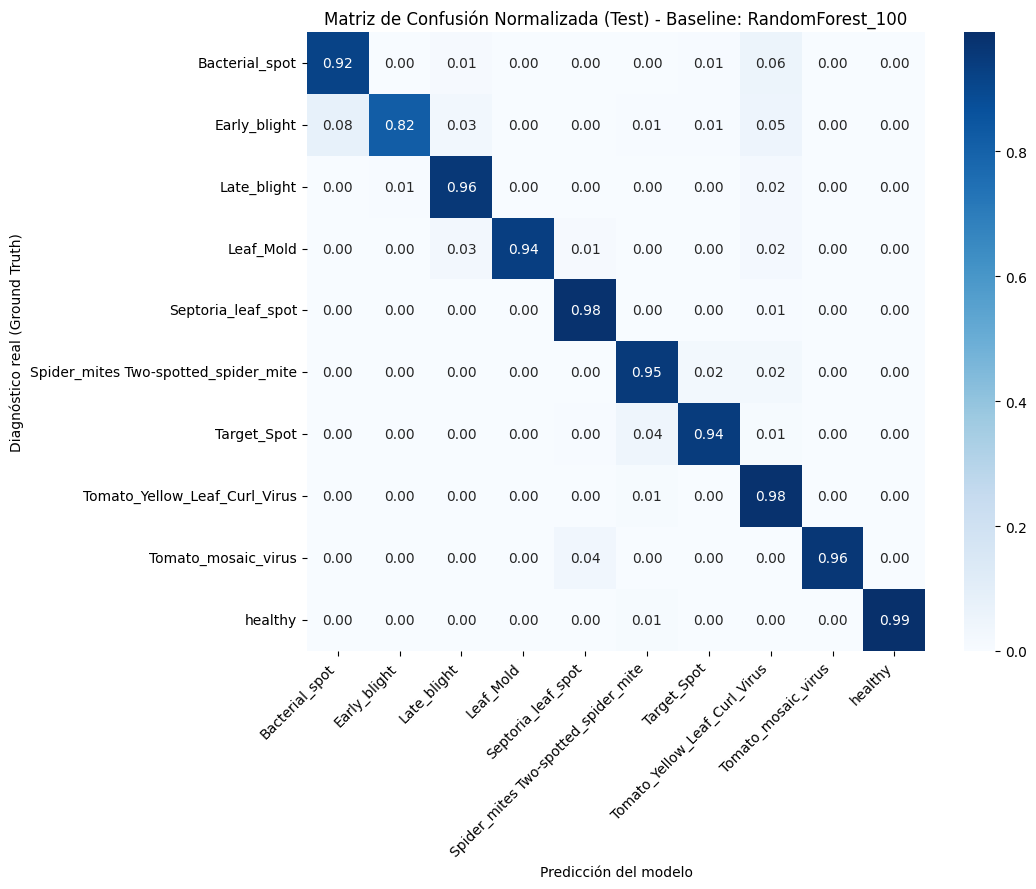

In [16]:
# Mapeo ordenado de nombres de clase
idx_to_label = (
    df_splits[["label_idx", "label"]]
    .drop_duplicates()
    .sort_values("label_idx")["label"]
    .tolist()
)

# Inferencia única sobre el conjunto de prueba (Test)
y_test_pred = best_model.predict(X_test)

test_acc = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted")

print(f"=== RESULTADOS FINALES BASELINE EN TEST ({best_name}) ===")
print(f"Accuracy Global : {test_acc:.4f}")
print(f"Macro F1-Score  : {test_macro_f1:.4f}")
print(f"Weighted F1     : {test_weighted_f1:.4f}\n")

print("Reporte detallado por patología:")
print(classification_report(y_test, y_test_pred, target_names=idx_to_label, digits=4))

# Matriz de confusión normalizada por fila (Recall por clase)
cm = confusion_matrix(y_test, y_test_pred, normalize="true")

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=idx_to_label,
    yticklabels=idx_to_label
)
plt.title(f"Matriz de Confusión Normalizada (Test) - Baseline: {best_name}")
plt.xlabel("Predicción del modelo")
plt.ylabel("Diagnóstico real (Ground Truth)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cm_baseline_test.png", dpi=300)
plt.show()

# Guardamos métricas en JSON para comparar automáticamente contra ResNet en el Notebook 3
metrics_summary = {
    "model_name": f"Baseline ({best_name})",
    "test_accuracy": round(float(test_acc), 4),
    "test_macro_f1": round(float(test_macro_f1), 4),
    "test_weighted_f1": round(float(test_weighted_f1), 4)
}
with open(RESULTS_DIR / "baseline_metrics.json", "w") as f:
    json.dump(metrics_summary, f, indent=4)

In [17]:
from google.colab import files

files.download("/content/plantvillage_tomate/results_baseline/cm_baseline_test.png")
files.download("/content/plantvillage_tomate/results_baseline/baseline_metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>